# Sensor virtual de sílice en la flotación de mineral de hierro

**Autor:** Cristian Camilo Piñeros Bautista  
**Proyecto integrador de Machine Learning**

## Problema y objetivo

En una planta de flotación, el operador dispone de mediciones de aire,
niveles de columna y dosificación de reactivos mientras espera el análisis
de laboratorio del concentrado. El objetivo de este proyecto es estimar,
al cierre de cada hora, el porcentaje de sílice del concentrado.

Se evalúan dos escenarios: uno basado en las señales de proceso y otro que
incorpora el resultado de sílice de tres horas antes. Este retraso es un
supuesto de disponibilidad. La persistencia de ese último valor sirve como
referencia para evaluar cuánto aportan los modelos.

[Repositorio del proyecto](https://github.com/CristianPB14/flotation-silica-soft-sensor)


## Fuente y preparación de los datos

El proyecto utiliza el conjunto *Quality Prediction in a Mining Process*,
que contiene 737.453 registros y 24 columnas de una planta de flotación de
mineral de hierro. Los registros abarcan del 10 de marzo al 9 de septiembre
de 2017 e incluyen flujos de reactivos y pulpa, pH, densidad, aire y niveles
de siete columnas de flotación, así como la composición de la alimentación
y del concentrado. [Fuente del dataset en Kaggle](https://www.kaggle.com/datasets/edumagalhaes/quality-prediction-in-a-mining-process)

La preparación se organizó en tres capas:

| Capa | Transformación realizada | Resultado |
|---|---|---|
| Bronze | Conversión de fechas y números con coma decimal, normalización de encabezados y escritura en Parquet. | 737.453 registros con tipos definidos. |
| Silver | Validación de nulos, porcentajes, flujos, densidad y rango de revisión del pH. | Los 737.453 registros pasaron las cinco comprobaciones. |
| Gold | Agregación de 19 señales de proceso por hora y construcción de variables de dosificación, aire, niveles e historia reciente. | 4.091 horas comparables para modelado y evaluación. |

### Definición del objetivo horario

El sensor estima el porcentaje de sílice del concentrado al cierre de cada hora.
Se observaron 4.097 horas con datos. En 3.787, todas las filas compartían un único
valor de sílice. En las otras 310 se encontraron secuencias compatibles con una
interpolación. Se adoptó la media de los valores registrados como objetivo horario
y se conservaron esas horas identificadas para analizar sus errores por separado.

En marzo hubo un intervalo de 318 horas consecutivas sin registros. Los rezagos
se calcularon sobre un calendario horario completo para respetar esa interrupción.
Las primeras tres horas del registro y las primeras tres posteriores al hueco
carecían del historial requerido, lo que dejó 4.091 horas para la comparación.

### Modelos y evaluación temporal

Se compararon Ridge, bosque aleatorio y vecinos más cercanos en dos escenarios.
El primero utilizó 84 variables derivadas de las señales de proceso. El segundo
añadió la sílice de tres horas antes, bajo el supuesto de que ese resultado ya
estaría disponible para el operador. El hierro del concentrado se excluyó de
las entradas porque se conoce junto con la sílice que se busca predecir.

Las últimas 819 horas se reservaron para la prueba final. En el período anterior,
los hiperparámetros se seleccionaron mediante cinco particiones cronológicas y
se compararon las configuraciones en un bloque posterior de 655 horas. Antes de
la prueba final, los modelos se reajustaron con las 3.270 horas cuyas etiquetas
habrían estado disponibles al emitir la primera predicción de prueba.

La métrica principal fue el error absoluto medio (MAE), expresado en puntos
porcentuales de sílice. Como referencias se usaron la media del entrenamiento
y la persistencia del valor de tres horas antes. También se reportaron el RMSE,
que da mayor peso a los errores grandes, y el coeficiente de determinación R².

In [1]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


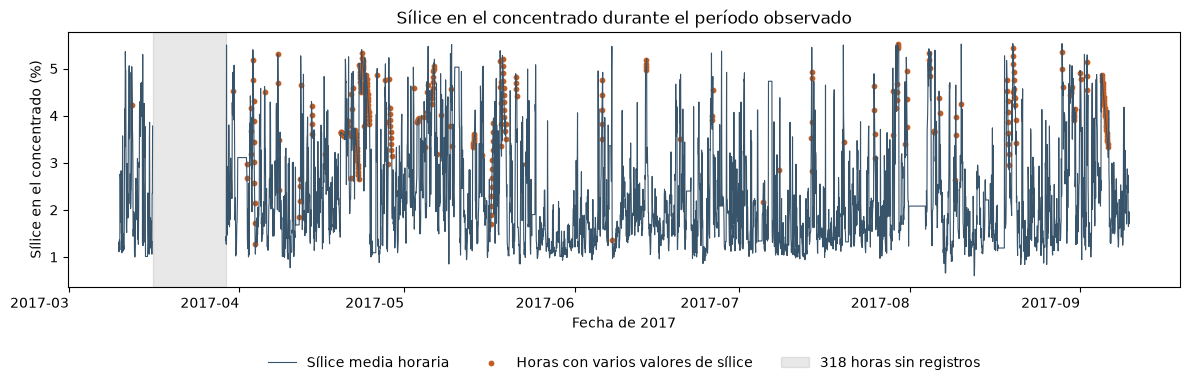

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

actual = Path.cwd()
raiz = next(
    ruta for ruta in (actual, *actual.parents)
    if (ruta / "data" / "silver" / "flotacion.parquet").is_file()
)

datos = pd.read_parquet(
    raiz / "data" / "silver" / "flotacion.parquet",
    columns=["date", "pct_silica_concentrate"],
)

horario = (
    datos.groupby("date")["pct_silica_concentrate"]
    .agg(silice_media="mean", valores_distintos="nunique")
    .asfreq("h")
)
varios = horario["valores_distintos"] > 1

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(
    horario.index, horario["silice_media"],
    color="#38546B", linewidth=0.8, label="Sílice media horaria",
)
ax.scatter(
    horario.index[varios], horario.loc[varios, "silice_media"],
    color="#C65D20", s=10, label="Horas con varios valores de sílice",
)
ax.axvspan(
    pd.Timestamp("2017-03-16 06:00"), pd.Timestamp("2017-03-29 12:00"),
    color="gray", alpha=0.18, label="318 horas sin registros",
)

ax.set(title="Sílice en el concentrado durante el período observado",
       xlabel="Fecha de 2017", ylabel="Sílice en el concentrado (%)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
fig.autofmt_xdate(rotation=0)
fig.tight_layout()
plt.show()

**Figura 1. Evolución horaria de la sílice en el concentrado.** La franja gris
señala 318 horas consecutivas sin registros. Los puntos naranjas identifican
las 310 horas en las que se registró más de un valor de sílice y se utilizó
su media como objetivo horario. Estas horas se marcaron para analizar por
separado el error de predicción.

In [3]:
variables = {
    "ore_pulp_ph": "pH de la pulpa",
    "ore_pulp_density": "Densidad de la pulpa",
    "ore_pulp_flow": "Flujo de pulpa",
    "amina_flow": "Flujo de amina",
    "starch_flow": "Flujo de almidón",
}

mediciones = pd.read_parquet(
    raiz / "data" / "silver" / "flotacion.parquet",
    columns=list(variables),
).rename(columns=variables)

estadisticas = mediciones.describe().T.rename(columns={
    "min": "Mínimo",
    "25%": "Percentil 25",
    "50%": "Mediana",
    "75%": "Percentil 75",
    "max": "Máximo",
})

estadisticas[["Mínimo", "Percentil 25", "Mediana", "Percentil 75", "Máximo"]].round(4)

,Mínimo,Percentil 25,Mediana,Percentil 75,Máximo
pH de la pulpa,8.7533,9.5274,9.7981,10.0380,10.8081
Densidad de la pulpa,1.5198,1.6473,1.6976,1.7283,1.8532
Flujo de pulpa,376.2490,394.2640,399.2490,402.9680,418.6410
Flujo de amina,241.6690,431.7960,504.3930,553.2570,739.5380
Flujo de almidón,0.0020,2076.3200,3018.4300,3727.7300,6300.2300


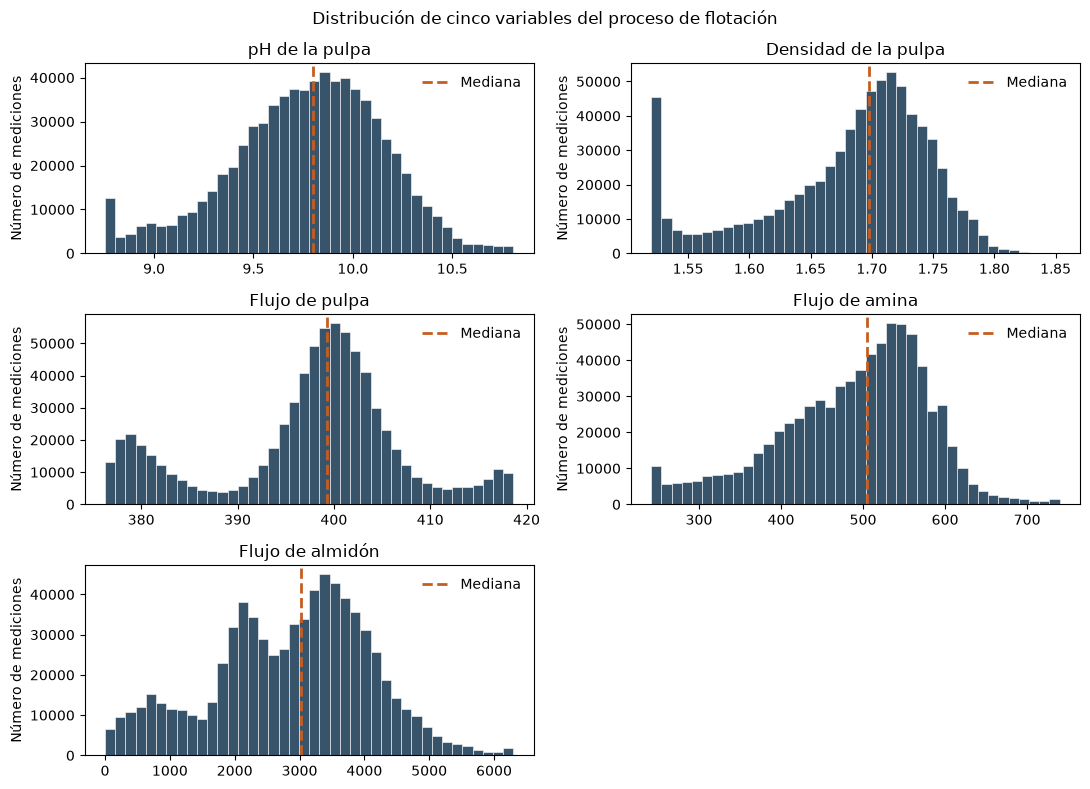

In [4]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(3, 2, figsize=(11, 8))

for ax, nombre in zip(ejes.flat, mediciones.columns):
    serie = mediciones[nombre].dropna()
    ax.hist(serie, bins=40, color="#38546B", edgecolor="white", linewidth=0.4)
    ax.axvline(
        serie.median(), color="#C65D20", linestyle="--",
        linewidth=2, label="Mediana"
    )
    ax.set_title(nombre)
    ax.set_ylabel("Número de mediciones")
    ax.legend(frameon=False)

ejes.flat[-1].set_visible(False)
fig.suptitle("Distribución de cinco variables del proceso de flotación")
fig.tight_layout()
plt.show()

La línea naranja indica la mediana de cada variable. El flujo de pulpa presenta su mayor concentración alrededor de 400 y un grupo menor cerca de 380. En el flujo de almidón se observan dos picos principales, uno cerca de 2.100 y otro alrededor de 3.400. La mediana de 3.018,43 resume el centro de las mediciones, mientras que el histograma permite distinguir esas dos concentraciones.

## Resultados en las 819 horas de prueba

In [5]:
from pathlib import Path
import pandas as pda

# Jupyter puede iniciarse desde la raíz del proyecto o desde notebooks/.
actual = Path.cwd()
raiz = next(
    ruta for ruta in (actual, *actual.parents)
    if (ruta / "reports" / "metricas_prueba.csv").is_file()
)

metricas = pd.read_csv(raiz / "reports" / "metricas_prueba.csv", index_col="metodo")
metricas.sort_values("MAE").round(3)


,MAE,RMSE,R2
metodo,,,
persistencia,0.679,0.995,0.244
bosque_proceso_laboratorio,0.738,0.935,0.333
ridge_proceso_laboratorio,0.753,0.953,0.307
knn_proceso_laboratorio,0.873,1.083,0.106
bosque_proceso,0.888,1.083,0.105
knn_proceso,0.903,1.123,0.038
ridge_proceso,0.904,1.107,0.064
media,0.947,1.145,-0.001


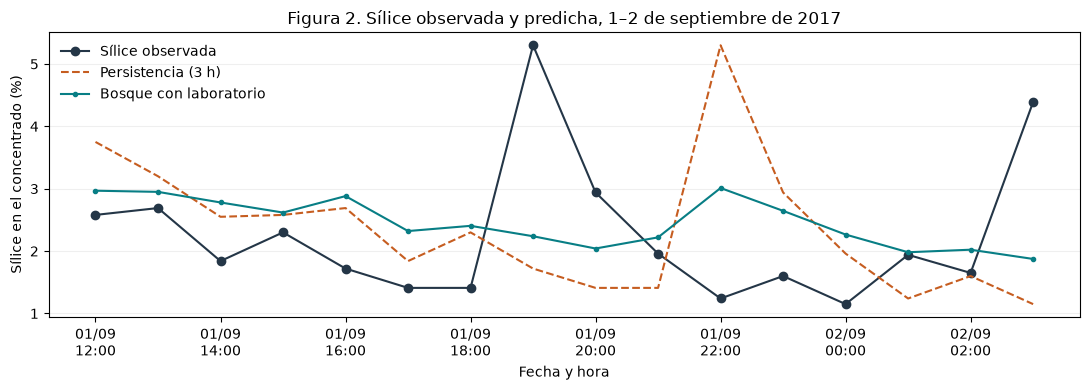

In [6]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

predicciones = pd.read_csv(
    raiz / "reports" / "predicciones_prueba.csv",
    parse_dates=["date"],
    index_col="date",
)

episodio = predicciones.loc["2017-09-01 12:00":"2017-09-02 03:00"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(episodio.index, episodio["silice_objetivo"],
        color="#243647", marker="o", label="Sílice observada")
ax.plot(episodio.index, episodio["persistencia"],
        color="#C65D20", linestyle="--", label="Persistencia (3 h)")
ax.plot(episodio.index, episodio["bosque_proceso_laboratorio"],
        color="#087E85", marker=".", label="Bosque con laboratorio")

ax.set(
    title="Figura 2. Sílice observada y predicha, 1–2 de septiembre de 2017",
    xlabel="Fecha y hora",
    ylabel="Sílice en el concentrado (%)",
)
ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Interpretación de los resultados

En las 819 horas de prueba, la persistencia obtuvo el menor error absoluto medio
(MAE), con 0,679 puntos porcentuales de sílice. Bajo el supuesto de que el
laboratorio entrega sus resultados con tres horas de retraso, utilizar la última
concentración disponible fue la estrategia más precisa según esta métrica.

El bosque aleatorio que combinó las señales de proceso con la sílice de tres
horas antes obtuvo el menor RMSE (0,935) y el mayor R² (0,333). Aunque su MAE
fue superior al de la persistencia, redujo algunos de los errores de mayor
magnitud. Por ejemplo, el 1 de septiembre a las 22:00, la persistencia estimó
5,30 % de sílice y el bosque estimó 3,01 %, frente a un valor observado de 1,24 %.

Cuando se utilizaron únicamente señales de proceso, el bosque obtuvo el menor
MAE en prueba (0,888). En la validación previa, KNN había obtenido el mejor
resultado de ese escenario (0,782). Por tanto, el orden de los modelos de solo
proceso cambió entre los dos períodos.

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

tabla = pd.read_parquet(raiz / "data" / "gold" / "features.parquet").sort_index()
objetivo = "silice_objetivo"

# Usar las mismas 655 horas de validación que en la comparación de modelos.
inicio_prueba = int(len(tabla) * 0.80)
inicio_validacion = int(inicio_prueba * 0.80)
validacion = tabla.iloc[inicio_validacion:inicio_prueba]

# Aplicar el supuesto de tres horas de retraso del laboratorio.
corte = validacion.index[0] - pd.Timedelta(hours=3)
entrenamiento = tabla.loc[:corte]

aparte = [objetivo, "silice_hace_3h", "lecturas", "valores_silice"]
columnas = tabla.drop(columns=aparte).columns.tolist() + ["silice_hace_3h"]

bosque = RandomForestRegressor(
    n_estimators=60,
    max_depth=6,
    min_samples_leaf=3,
    max_features=0.4,
    random_state=42,
    n_jobs=1,
)
bosque.fit(entrenamiento[columnas], entrenamiento[objetivo])

resultado = permutation_importance(
    bosque,
    validacion[columnas],
    validacion[objetivo],
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
)

importancias = pd.DataFrame({
    "variable": columnas,
    "aumento_mae": resultado.importances_mean,
    "desviacion_entre_repeticiones": resultado.importances_std,
}).sort_values("aumento_mae", ascending=False)

importancias.to_csv(raiz / "reports" / "importancia_permutacion.csv", index=False)
importancias.head(5).round(4)

,variable,aumento_mae,desviacion_entre_repeticiones
84,silice_hace_3h,0.1248,0.0149
47,flotation_column_07_air_flow_max,0.0085,0.0004
35,flotation_column_04_air_flow_max,0.0078,0.0004
20,flotation_column_01_air_flow_mean,0.0074,0.0018
74,flotation_column_07_level_min,0.0062,0.0009


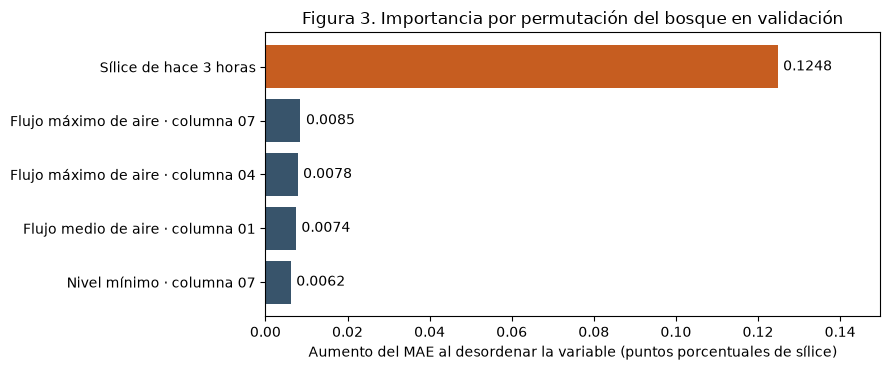

In [8]:
importancias = pd.read_csv(raiz / "reports" / "importancia_permutacion.csv")
principales = importancias.nlargest(5, "aumento_mae").sort_values("aumento_mae")

nombres = {
    "silice_hace_3h": "Sílice de hace 3 horas",
    "flotation_column_07_air_flow_max": "Flujo máximo de aire · columna 07",
    "flotation_column_04_air_flow_max": "Flujo máximo de aire · columna 04",
    "flotation_column_01_air_flow_mean": "Flujo medio de aire · columna 01",
    "flotation_column_07_level_min": "Nivel mínimo · columna 07",
}

fig, ax = plt.subplots(figsize=(9, 3.8))
barras = ax.barh(
    principales["variable"].replace(nombres),
    principales["aumento_mae"],
    color=["#C65D20" if v == "silice_hace_3h" else "#38546B"
           for v in principales["variable"]],
)
ax.bar_label(barras, fmt="%.4f", padding=4)
ax.set_xlim(0, principales["aumento_mae"].max() * 1.20)
ax.set(
    title="Figura 3. Importancia por permutación del bosque en validación",
    xlabel="Aumento del MAE al desordenar la variable (puntos porcentuales de sílice)",
)
fig.tight_layout()
plt.show()

**Figura 3.** En las 655 horas de validación, la sílice registrada tres horas antes fue la variable de mayor importancia individual para el bosque. Entre las señales de proceso destacó el flujo máximo de aire de la columna 07. Como varias señales de aire están relacionadas entre sí, el modelo puede conservar parte de la información de una columna cuando se desordena otra.

## Limitaciones y conclusión

Los datos corresponden a una sola planta entre marzo y septiembre de 2017. El retraso de tres horas del laboratorio se adoptó como supuesto porque el archivo registra la hora de la medición, pero carece de la hora de entrega del informe. Además, en 310 horas se observaron varios valores de sílice y se utilizó su media como objetivo. Conocer los tiempos reales de muestreo, análisis y entrega permitiría evaluar el sensor en condiciones más cercanas a las de operación.

La utilidad del sensor depende de la información disponible al cierre de cada hora. Con las señales de proceso, el bosque obtuvo un MAE de 0,888 puntos porcentuales en las 819 horas de prueba. Cuando se supuso disponible la sílice de tres horas antes, la persistencia alcanzó el menor MAE (0,679). El bosque que combinó ambas fuentes obtuvo el menor RMSE (0,935) y redujo el error en algunos cambios bruscos de concentración.

Para una evaluación en planta, el siguiente paso sería registrar cuándo recibe el operador cada resultado de laboratorio y acordar qué magnitud de error justificaría revisar la dosificación de reactivos o el aire de flotación. Ese criterio permitiría valorar la utilidad operativa de las predicciones.